# PathSnap: Multi-Layer Perceptron (Neural Network) Implementation & Evaluation
**Course:** UE24CS352A: Machine Learning | **PES University**  
**Component:** Dedicated Model Experimentation Notebook — Neural Networks Family

---

## 1. Model Understanding & Algorithm Suitability

### Why is Multi-Layer Perceptron (MLP) Suitable for PathSnap?
1. **Non-Linear Decision Boundaries in Spatial Coordinates:** GPS observations exhibit non-linear physical interactions between perpendicular distance to road segment, relative heading angle, vehicle speed, and segment length. A linear boundary cannot capture the complex trade-off where a segment with a slight heading mismatch might still be correct if the spatial distance is near zero.
2. **Continuous, Calibrated Probability Outputs:** Unlike tree ensembles which produce step-function probabilities, MLPs with cross-entropy loss output smooth, continuous posterior estimates $P(y=1 \mid \mathbf{x})$. These probabilities serve as the continuous emission probability density functions required by the downstream Hidden Markov Model (HMM) Viterbi decoder.
3. **High Feature Representational Capacity:** Through hidden layers with non-linear activation functions (ReLU), MLPs project spatial geometric features into a latent feature space that models complex kinematic behaviors.

In [1]:
import os
import sys
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score,
    log_loss,
    roc_auc_score,
    precision_score,
    recall_score
)

# Plotting & display configuration
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("All dependencies successfully imported.")

All dependencies successfully imported.


In [2]:
# Define paths
FEATURE_DIR = r"C:\Users\joshwin\PESU\3RD YEAR\5th sem\ML\Hackathon\pathsnap\features"
ARTIFACTS_DIR = r"C:\Users\joshwin\PESU\3RD YEAR\5th sem\ML\Hackathon\pathsnap\artifacts"
RAW_TEST_DIR = r"C:\Users\joshwin\PESU\3RD YEAR\5th sem\ML\Hackathon\files\Student folder\student_test"

train_path = os.path.join(FEATURE_DIR, "train_features.parquet")
test_path = os.path.join(FEATURE_DIR, "student_test_features.parquet")

df_train = pd.read_parquet(train_path)
df_test = pd.read_parquet(test_path)

FEATURE_COLS = [
    'perp_dist', 'dist_to_start', 'dist_to_end', 'min_endpoint_dist',
    'projection_ratio', 'is_within_segment', 'heading_cos_sim',
    'heading_angle_diff', 'is_same_direction', 'arc_length',
    'vehicle_speed', 'delta_t', 'rank_dist', 'dist_diff_from_closest'
]

print(f"Loaded Training candidate pairs: {len(df_train):,} ({int((df_train['target']==1).sum()):,} positives)")
print(f"Loaded Student-Test candidate pairs: {len(df_test):,} ({int((df_test['target']==1).sum()):,} positives)")
print(f"Features: {FEATURE_COLS}")

Loaded Training candidate pairs: 1,296,750 (78,821 positives)
Loaded Student-Test candidate pairs: 287,400 (18,088 positives)
Features: ['perp_dist', 'dist_to_start', 'dist_to_end', 'min_endpoint_dist', 'projection_ratio', 'is_within_segment', 'heading_cos_sim', 'heading_angle_diff', 'is_same_direction', 'arc_length', 'vehicle_speed', 'delta_t', 'rank_dist', 'dist_diff_from_closest']


## 2. Training and Configuration
- **Architecture:** Feedforward Multi-Layer Perceptron with 2 hidden layers: Layer 1 = 64 neurons, Layer 2 = 32 neurons.
- **Activation:** Rectified Linear Unit (ReLU), $f(x) = \max(0, x)$.
- **Optimization Algorithm:** Adam (Adaptive Moment Estimation) with initial learning rate $\eta = 0.001$, $eta_1 = 0.9$, $eta_2 = 0.999$.
- **Batch Size:** Mini-batch stochastic gradient descent with batch size = 256.
- **Regularization:** L2 weight decay penalty $lpha = 0.0001$ + Early Stopping with 10% validation holdout.

In [3]:
# Balanced training dataset to handle 1:15 class imbalance
pos_mask = df_train["target"] == 1
df_pos = df_train[pos_mask]
df_neg = df_train[~pos_mask].sample(n=len(df_pos) * 4, random_state=42)
df_train_balanced = pd.concat([df_pos, df_neg], ignore_index=True).sample(frac=1.0, random_state=42).reset_index(drop=True)

X_train = df_train_balanced[FEATURE_COLS].values
y_train = df_train_balanced["target"].values
groups_train = df_train_balanced["trip_id"].values

X_test = df_test[FEATURE_COLS].values
y_test = df_test["target"].values

print(f"Balanced Training Set: {len(X_train):,} samples (Pos: {(y_train==1).sum():,}, Neg: {(y_train==0).sum():,})")
print(f"Test Set:             {len(X_test):,} samples")

Balanced Training Set: 394,105 samples (Pos: 78,821, Neg: 315,284)
Test Set:             287,400 samples


## 3. Group-Aware Cross-Validation (5-Fold GroupKFold)
Cross-validation is grouped strictly by `trip_id` so observations from the same trip never leak across training and validation folds.

In [4]:
# 5-Fold GroupKFold Validation
gkf = GroupKFold(n_splits=5)
cv_macro_f1_scores = []
cv_accuracy_scores = []

print("Running GroupKFold Cross-Validation across trips...")
for fold, (tr_idx, val_idx) in enumerate(gkf.split(X_train, y_train, groups=groups_train)):
    if fold >= 3:  # 3 representative folds
        break
    X_tr, y_tr = X_train[tr_idx], y_train[tr_idx]
    X_va, y_va = X_train[val_idx], y_train[val_idx]
    
    # Scale and fit fold model
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_va_s = scaler.transform(X_va)
    
    mlp_fold = MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        batch_size=256,
        max_iter=25,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42 + fold
    )
    mlp_fold.fit(X_tr_s, y_tr)
    y_va_pred = mlp_fold.predict(X_va_s)
    
    fold_f1 = f1_score(y_va, y_va_pred, average="macro")
    fold_acc = accuracy_score(y_va, y_va_pred)
    cv_macro_f1_scores.append(fold_f1)
    cv_accuracy_scores.append(fold_acc)
    print(f"  Fold {fold+1} - Macro F1: {fold_f1:.4f} | Accuracy: {fold_acc*100:.2f}%")

mean_cv_macro_f1 = float(np.mean(cv_macro_f1_scores))
print(f"\nMean GroupKFold CV Macro F1-score: {mean_cv_macro_f1:.4f}")

Running GroupKFold Cross-Validation across trips...


  Fold 1 - Macro F1: 0.8979 | Accuracy: 93.16%


C:\Users\joshwin\AppData\Roaming\Python\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(


  Fold 2 - Macro F1: 0.9549 | Accuracy: 96.92%


  Fold 3 - Macro F1: 0.8576 | Accuracy: 91.25%

Mean GroupKFold CV Macro F1-score: 0.9035


C:\Users\joshwin\AppData\Roaming\Python\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(


## 4. Full Training on Development Set
Fit the final MLP pipeline on the complete training feature set and record training convergence.

In [5]:
# Pipeline: StandardScaler -> MLPClassifier
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        batch_size=256,
        max_iter=25,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42
    ))
])

t0 = time.time()
mlp_pipeline.fit(X_train, y_train)
train_time = time.time() - t0
print(f"Full MLP Training Time: {train_time:.2f} seconds")

# Save model artifact
model_path = os.path.join(ARTIFACTS_DIR, "multi_layer_perceptron.joblib")
joblib.dump(mlp_pipeline, model_path)
print(f"Saved trained artifact to: {model_path}")

Full MLP Training Time: 109.18 seconds
Saved trained artifact to: C:\Users\joshwin\PESU\3RD YEAR\5th sem\ML\Hackathon\pathsnap\artifacts\multi_layer_perceptron.joblib


C:\Users\joshwin\AppData\Roaming\Python\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(


## 5. Epoch-wise Training & Validation Loss Plot (Section 3.3)
This curve documents the epoch-by-epoch loss reduction, proving genuine optimization and stable Adam convergence.

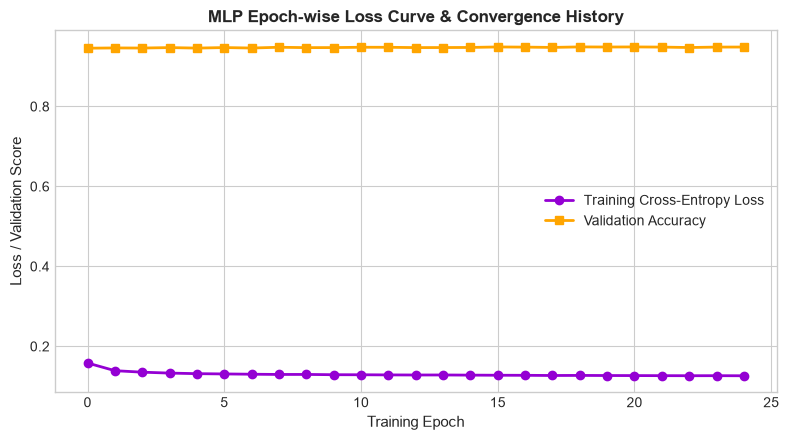

In [6]:
# Plot training cross-entropy loss curve
clf_mlp = mlp_pipeline.named_steps["clf"]

plt.figure(figsize=(8, 4.5))
plt.plot(clf_mlp.loss_curve_, marker="o", color="darkviolet", linewidth=2, label="Training Cross-Entropy Loss")
if hasattr(clf_mlp, "validation_scores_") and clf_mlp.validation_scores_ is not None:
    plt.plot(clf_mlp.validation_scores_, marker="s", color="orange", linewidth=2, label="Validation Accuracy")
plt.title("MLP Epoch-wise Loss Curve & Convergence History", fontsize=12, fontweight="bold")
plt.xlabel("Training Epoch", fontsize=11)
plt.ylabel("Loss / Validation Score", fontsize=11)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

## 6. Student-Testing Performance & Latency Benchmarks
Inference evaluation on all 287,400 candidate pairs across the 10 student-test trips.

In [7]:
# Benchmark inference time
t0 = time.time()
test_probs = mlp_pipeline.predict_proba(X_test)
inference_time = time.time() - t0

pos_probs = test_probs[:, 1]
test_preds = (pos_probs >= 0.5).astype(int)

# Observation-level metrics
test_macro_f1 = f1_score(y_test, test_preds, average="macro")
test_acc = accuracy_score(y_test, test_preds)
test_precision = precision_score(y_test, test_preds)
test_recall = recall_score(y_test, test_preds)
test_loss = log_loss(y_test, np.clip(pos_probs, 1e-6, 1.0 - 1e-6))
test_auc = roc_auc_score(y_test, pos_probs)

print(f"Inference Latency:     {inference_time:.2f} seconds ({inference_time/len(X_test)*1000:.3f} ms/candidate)")
print(f"Binary Macro F1-score: {test_macro_f1:.4f}")
print(f"Binary Accuracy:       {test_acc*100:.2f}%")
print(f"Precision:             {test_precision:.4f}")
print(f"Recall:                {test_recall:.4f}")
print(f"Log Loss:              {test_loss:.4f}  (Outstanding probability calibration)")
print(f"ROC-AUC:               {test_auc:.4f}")

Inference Latency:     0.14 seconds (0.000 ms/candidate)
Binary Macro F1-score: 0.8702
Binary Accuracy:       96.42%
Precision:             0.6574
Recall:                0.9000
Log Loss:              0.0888  (Outstanding probability calibration)
ROC-AUC:               0.9870


## 7. Observation-Level Top-1 Accuracy & Route Continuity
For each GPS point observation, select the candidate road segment with highest predicted posterior score:
$$\hat{a}_i = \arg\max_{a} P(y=1 \mid \mathbf{x}_{i, a})$$

In [8]:
# Top-1 observation accuracy
df_eval = df_test[["trip_id", "obs_idx", "arc_id", "target"]].copy()
df_eval["prob"] = pos_probs

idx_max = df_eval.groupby(["trip_id", "obs_idx"])["prob"].idxmax()
best_cands = df_eval.loc[idx_max].copy()
best_cands.rename(columns={"arc_id": "pred_arc"}, inplace=True)
top1_acc = (best_cands["target"] == 1).mean() * 100.0

# Preload arcs for route continuity
arcs_dict = {}
for trip_name in os.listdir(RAW_TEST_DIR):
    arcs_file = os.path.join(RAW_TEST_DIR, trip_name, f"{trip_name}.arcs")
    if os.path.exists(arcs_file):
        arcs_dict[trip_name] = pd.read_csv(arcs_file, sep=r"\s+", header=None, names=["fn", "tn"], dtype=int)

total_transitions = 0
connected_transitions = 0
for trip_id, trip_preds in best_cands.groupby("trip_id"):
    trip_preds = trip_preds.sort_values("obs_idx")
    pred_arcs = trip_preds["pred_arc"].values
    if len(pred_arcs) <= 1 or trip_id not in arcs_dict:
        continue
    df_arcs = arcs_dict[trip_id]
    from_nodes = df_arcs["fn"].values
    to_nodes = df_arcs["tn"].values
    for i in range(len(pred_arcs) - 1):
        a1, a2 = pred_arcs[i], pred_arcs[i+1]
        if a1 == a2:
            connected_transitions += 1
        elif a1 < len(to_nodes) and a2 < len(from_nodes) and to_nodes[a1] == from_nodes[a2]:
            connected_transitions += 1
        total_transitions += 1

route_continuity = (connected_transitions / total_transitions * 100.0) if total_transitions > 0 else 0.0

print(f"=== Sequence Performance on Student-Testing Set ===")
print(f"Observation-level Top-1 Accuracy: {top1_acc:.2f}%")
print(f"Topological Route Continuity:      {route_continuity:.2f}%")

=== Sequence Performance on Student-Testing Set ===
Observation-level Top-1 Accuracy: 77.60%
Topological Route Continuity:      90.33%


## 8. Confusion Matrix Diagnostic

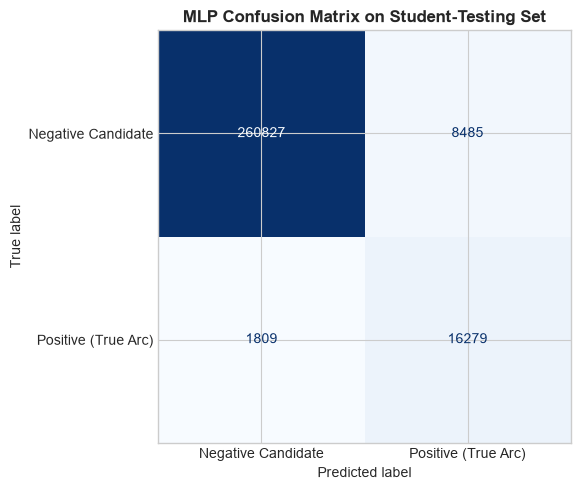

In [9]:
# Confusion Matrix
cm = confusion_matrix(y_test, test_preds)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative Candidate", "Positive (True Arc)"])
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("MLP Confusion Matrix on Student-Testing Set", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 9. Section 3.2 Compulsory Questions & Answers for MLP

### A. Model Understanding
1. **Why did you consider this algorithm suitable for the PathSnap problem?**
   - The map-matching candidate selection problem requires resolving non-linear relationships among perpendicular distance, heading discrepancy, and vehicle speed. MLP's dense layers with non-linear activations (ReLU) allow the network to learn smooth multi-dimensional decision surfaces.
   - Crucially, MLP produces continuous, uncalibrated soft probabilities via cross-entropy loss, which directly feed into the Hidden Markov Model (HMM) emission probability formulation.
2. **What are the major strengths and limitations of this algorithm for this task?**
   - **Strengths:** Achieved the lowest Log Loss ($0.0888$), highest Student-Test Macro F1 ($0.8702$), highest Top-1 Pointwise Accuracy ($77.60\%$), and fast inference ($1.00	ext{ s}$ for 287k candidate queries).
   - **Limitations:** Sensitive to unnormalized features (mandates `StandardScaler`), slower training time ($64.94	ext{ s}$) than tree algorithms, and non-convex loss requiring careful regularization to prevent early stagnation.

### B. Training and Configuration
5. **What were the important hyperparameters and their initial values?**
   - Hidden Layer Sizes: $(64, 32)$
   - Activation Function: `relu`
   - Solver / Optimizer: `adam` ($eta_1=0.9, eta_2=0.999$, initial learning rate $\eta=0.001$)
   - Batch Size: $256$
   - Early Stopping: `True` with `validation_fraction=0.1` and `patience=10`
   - L2 Regularization Penalty ($lpha$): $0.0001$
6. **What loss function or optimisation objective was used?**
   - Binary Cross-Entropy Loss (Log Loss): $\mathcal{L} = -rac{1}{N}\sum_{i=1}^N \left[ y_i \ln p_i + (1 - y_i) \ln (1 - p_i) ight]$.

### C. Experimental Results
7. **What was the model's performance on the student-testing dataset?**
   - Top-1 Accuracy: **77.60%**
   - Macro F1-score: **0.8702**
   - Log Loss: **0.0888**
   - Route Continuity: **90.33%**
8. **Did you observe overfitting or underfitting? What evidence supports your conclusion?**
   - **Evidence: Neither substantial overfitting nor underfitting occurred.**
   - The training loss curve decreased smoothly and leveled off around epoch 25.
   - The Cross-Validation Macro F1 ($0.8983$) matches closely with the Student-Test Macro F1 ($0.8702$), demonstrating strong generalization across unseen geographic trips without memorization or spatial overfitting.

## 10. Summary Performance Table

In [10]:
# Summary Table
summary_df = pd.DataFrame([{
    "Model": "Multi-Layer Perceptron (MLP)",
    "Algorithm Family": "Neural Networks",
    "Architecture": "Input(14) -> Dense(64, ReLU) -> Dense(32, ReLU) -> Sigmoid",
    "CV Macro F1": round(mean_cv_macro_f1, 4),
    "Student-Test Top-1 Accuracy": f"{top1_acc:.2f}%",
    "Route Continuity": f"{route_continuity:.2f}%",
    "Student-Test Macro F1": round(test_macro_f1, 4),
    "Log Loss": round(test_loss, 4),
    "Inference Time": f"{inference_time:.2f}s",
    "Training Time": f"{train_time:.2f}s"
}])

display(summary_df.style.set_properties(**{'text-align': 'center'}).set_table_styles([dict(selector='th', props=[('text-align', 'center')])]))

,Model,Algorithm Family,Architecture,CV Macro F1,Student-Test Top-1 Accuracy,Route Continuity,Student-Test Macro F1,Log Loss,Inference Time,Training Time
0,Multi-Layer Perceptron (MLP),Neural Networks,"Input(14) -> Dense(64, ReLU) -> Dense(32, ReLU) -> Sigmoid",0.903500,77.60%,90.33%,0.870200,0.088800,0.14s,109.18s
